In [2]:
# Run this cell if the required packages are not already installed.
%pip install -q tensorflow tensorflow-hub opencv-python matplotlib
%pip install --upgrade pip
%pip install setuptools==80.9.0

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
  Using cached setuptools-80.9.0-py3-none-any.whl.metadata (6.6 kB)
Using cached setuptools-80.9.0-py3-none-any.whl (1.2 MB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 84.2.1
    Uninstalling setuptools-84.2.1:
      Successfully uninstalled setuptools-84.2.1
Note: you may need to restart the kernel to use updated packages.


In [3]:
import tensorflow as tf
import tensorflow_hub as hub
import cv2
import matplotlib.pyplot as plt

/home/lenovo/.pyenv/versions/3.10.13/lib/python3.10/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [4]:
model = hub.load("https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2")
print("SSD MobileNetV2 model loaded successfully")

E0000 00:00:1794851113.847748    8784 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


SSD MobileNetV2 model loaded successfully


In [7]:
image_path = "testm.jpeg"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError("Image not found!")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image)
plt.axis("off")
plt.show()

[ WARN:0@216.268] global loadsave.cpp:278 findDecoder imread_('testm.jpeg'): can't open/read file: check file path/integrity


FileNotFoundError: Image not found!

In [9]:
input_image = tf.convert_to_tensor(image, dtype=tf.uint8)
input_image = tf.expand_dims(input_image, axis=0)

print("Input tensor shape:", input_image.shape)

ValueError: Attempt to convert a value (None) with an unsupported type (<class 'NoneType'>) to a Tensor.

In [10]:
result = model(input_image)
print("Detection completed")
print("Available result keys:", list(result.keys()))

NameError: name 'input_image' is not defined

In [11]:
boxes = result["detection_boxes"][0].numpy()
classes = result["detection_classes"][0].numpy()
scores = result["detection_scores"][0].numpy()

print("Number of detections returned:", len(scores))

NameError: name 'result' is not defined

In [12]:
h, w, _ = image.shape

labels = {
    1: "person",
    2: "bicycle",
    3: "car",
    4: "motorcycle",
    5: "airplane",
    6: "bus",
    7: "train",
    8: "truck",
    9: "boat",
    17: "cat",
    18: "dog",
    19: "horse",
    20: "sheep",
    21: "cow"
}

for i in range(len(scores)):
    if scores[i] > 0.5:
        y1, x1, y2, x2 = boxes[i]

        x1, x2 = int(x1 * w), int(x2 * w)
        y1, y2 = int(y1 * h), int(y2 * h)

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

        class_id = int(classes[i])
        label = labels.get(class_id, "Object")
        cv2.putText(
            image, label, (x1, max(y1 - 10, 0)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2
        )

print("Bounding boxes drawn for detections with confidence > 0.5")

AttributeError: 'NoneType' object has no attribute 'shape'

TypeError: Image data of dtype object cannot be converted to float

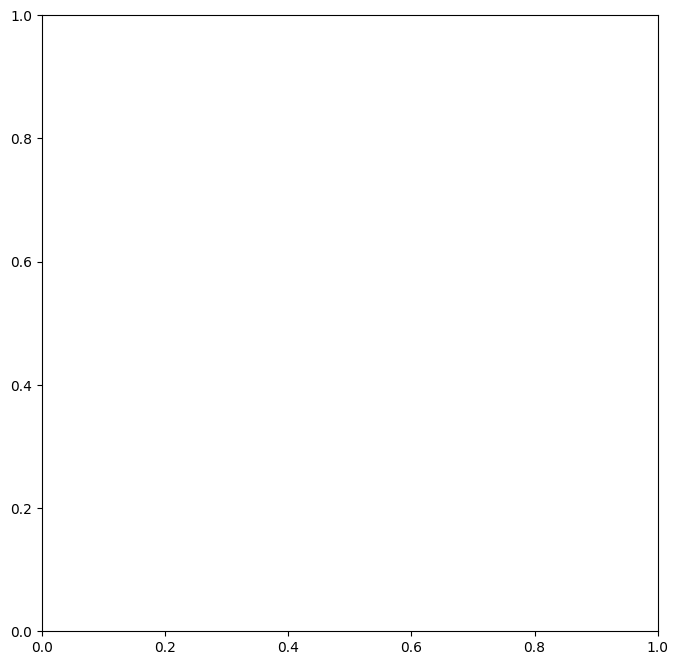

In [13]:
plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis('off')
plt.title('Object Detection using SSD MobileNetV2')
plt.show()